Implement logistic regression model to predict the likelihood of a disease using the Pima Indians Diabetes dataset. Compare the performance with and without feature scaling.

Step 1: Load and Preprocess the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix
# Load dataset from URL or local path
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI',
'DiabetesPedigree', 'Age', 'Outcome']
df = pd.read_csv(url, names=columns)
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values
# Split into Train and Test splits (70/30 layout for stable variance observation)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Step 2: Train Logistic Regression Without Feature Scaling

In [2]:
# Fit model with a fixed solver constraint to examine unscaled gradient environments
model_unscaled = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
model_unscaled.fit(X_train, y_train)
y_pred_unscaled = model_unscaled.predict(X_test)

C:\Users\Dell\PycharmProjects\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Step 3: Train Logistic Regression With Feature Scaling

In [3]:
# Apply Standardization pipeline
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model_scaled = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
model_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = model_scaled.predict(X_test_scaled)

Step 4: Performance Generation Matrix

In [4]:
def calculate_metrics(y_true, y_pred, label):
    return {
        'Framework': label,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }
res_unscaled = calculate_metrics(y_test,y_pred_unscaled, 'Without Scaling')
res_scaled = calculate_metrics(y_test, y_pred_scaled, 'With Scaling (Standardized)')
metrics_df = pd.DataFrame([res_unscaled, res_scaled])
print(metrics_df.to_string(index=False))

                  Framework  Accuracy  Precision  Recall  F1-Score
            Without Scaling  0.701299   0.612245   0.375  0.465116
With Scaling (Standardized)  0.735931   0.617284   0.625  0.621118


Step 5: Visualize Coefficient Magnitude Discrepancies

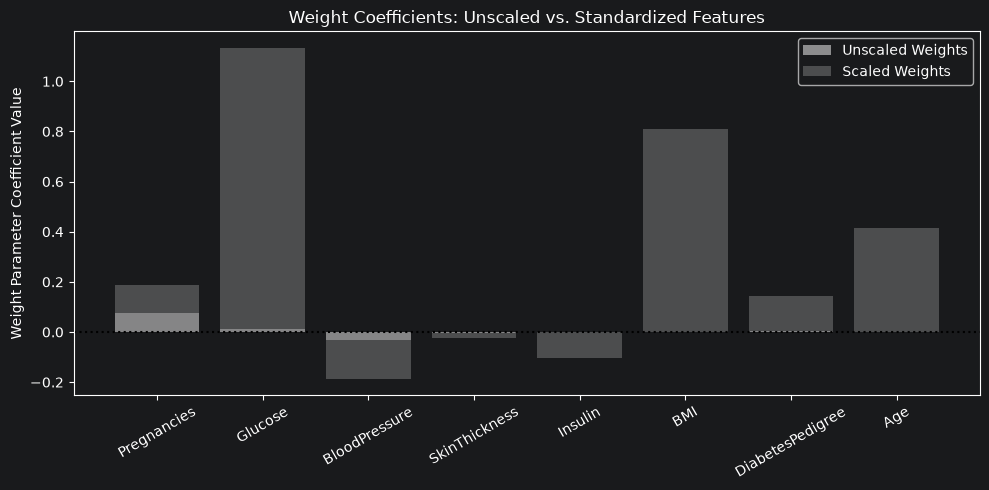

In [5]:
plt.figure(figsize=(10, 5))
plt.bar(columns[:-1], model_unscaled.coef_[0], alpha=0.5, label='Unscaled Weights', color='white')
plt.bar(columns[:-1], model_scaled.coef_[0], alpha=0.5, label='Scaled Weights', color='grey')
plt.axhline(0, color='black', linestyle=':')
plt.xticks(rotation=30)
plt.ylabel('Weight Parameter Coefficient Value')
plt.title('Weight Coefficients: Unscaled vs. Standardized Features')
plt.legend()
plt.tight_layout()
plt.show()